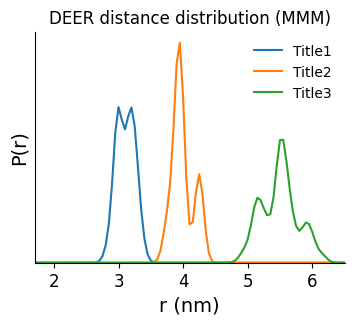

In [66]:
# ============================================================
# Plotting MMM Distance Distributions
#
# This script loads distance distributions obtained from MMM
# simulations and plots them for comparison.
#
# The script can handle any number of datasets (currently set up for three).
# All distributions are normalized to the highest peak.
#
# Input: MMM simulation data (distr.dat)
# Output: PNG (600 dpi) and PDF figures
#
# Required libraries: NumPy, Matplotlib
# Author: Alexey Chubarov https://github.com/chubarov-lab
# Date: 2026-11-20
# License: MIT
# See LICENSE file for details.
# ============================================================
import os
import numpy as np
import matplotlib.pyplot as plt

# Output folder for saving the figures
out_folder = r"C:\path\Folder"
if not os.path.exists(out_folder):
    os.makedirs(out_folder)

# Input MMM files and legend labels 
# Comment out unused datasets or add new ones as needed.
files_info = [
     {
        "file_path": r"S:\path\File1_distr.dat",
        "legend_label": "Title1"
    },
    {
        "file_path": r"S:\path\File2_distr.dat",
        "legend_label": "Title2"
    },
     {
        "file_path": r"S:\path\File3_distr.dat",
        "legend_label": "Title3"
    },
       ]
# Find the highest probability across all datasets
max_P = max(
    np.max(np.loadtxt(item["file_path"])[:, 1])
    for item in files_info
    if os.path.exists(item["file_path"])
)
# Create figure
plt.figure(figsize=(4, 3))
for item in files_info:
    file_path = item["file_path"]
    legend_label = item["legend_label"]

    if os.path.exists(file_path):
        try:
            data = np.loadtxt(file_path)
            r = data[:, 0]
            P = data[:, 1]
            P = P / max_P # Normalize all distributions to the highest peak
            plt.plot(r, P, label=legend_label)
        except Exception as e:
            print(f"Could not load {file_path}: {e}")
    else:
        print(f"File not found: {file_path}")   

# Configure plot
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlim(1.7, 6.5)
plt.ylim(0, 1.05)
plt.gca().set_yticks([])
plt.xlabel('r (nm)', fontsize=14)
plt.tick_params(axis='x', labelsize=12)
plt.ylabel('P(r)', fontsize=14)
plt.title("DEER distance distribution (MMM)")
plt.legend(frameon=False, loc="upper right")
out_path = os.path.join(out_folder, "File_Title.png") 
plt.savefig(out_path, dpi=600, bbox_inches='tight')
out_path_pdf = os.path.join(out_folder, "File_Title.pdf")
plt.savefig(out_path_pdf, bbox_inches="tight")
plt.show()